In [4]:
import cv2
def resize_with_aspect_ratio(image, width=None, height=None, inter=cv2.INTER_AREA):
    dim = None
    (h, w) = image.shape[:2]
    
    if width is None and height is None:
        return image
        
    if width is None:
        r = height / float(h)
        dim = (int(w * r), height)
    else:
        r = width / float(w)
        dim = (width, int(h * r))
        
    return cv2.resize(image, dim, interpolation=inter)

# Пример использования


In [2]:
import cv2
import numpy as np

# Загрузка изображения
img = cv2.imread("4_practice_sharik.jpg")

# Сглаживаем изображение, чтобы шум не мешал
blur = cv2.GaussianBlur(img, (7, 7), 0)

# Переводим в HSV
hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)


lower = np.array([15, 90, 90])
upper = np.array([40, 255, 255])
mask = cv2.inRange(hsv, lower, upper)



# УВЕЛИЧЕННОЕ ядро — убирает ленту
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

# Удаляем тонкие объекты (лента)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Заполняем шарик полностью
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)



# Оставляем только объект интереса
result = cv2.bitwise_and(img, img, mask=mask)



cv2.imshow("original", img)
cv2.imshow("mask_blur", mask)
cv2.imshow("result_blur", result)

cv2.waitKey(0)
cv2.destroyAllWindows()
    

Заполнить дырку, увеличить ядра,cv2.bitwise_and()

In [3]:
import cv2
import numpy as np

img = cv2.imread("4_practice_kristall.jpg")



# Переводим в HSV
hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)

# Диапазон синего/фиолетового 
lower = np.array([105, 40, 40])  
upper = np.array([145, 255, 255])

# Создаем маску
mask = cv2.inRange(hsv, lower, upper)

# Морфология для устранения мелких шумов
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7,7))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)


resized_or = resize_with_aspect_ratio(img, width=500) 
resized_mask_blur = resize_with_aspect_ratio(mask_blur, width=500) 
resized_result = resize_with_aspect_ratio(result, width=500) 
cv2.imshow("original", resized_or)
cv2.imshow("mask_blur", resized_mask_blur)
cv2.imshow("result_blur", resized_result)
cv2.waitKey(0)
cv2.destroyAllWindows()


NameError: name 'resize_with_aspect_ratio' is not defined

сделать расширение для морфологии, сделать верх маски черным, поменять диапазон upper сделать меньше 


In [9]:
import cv2
import numpy as np

# Загрузка изображения
img = cv2.imread("4_practice_kristall.jpg")


hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

lower = np.array([110, 0, 0], np.uint8)
upper = np.array([120, 255, 255], np.uint8)

mask = cv2.inRange(hsv, lower, upper)


kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_open, iterations=3)
opened[:200] = 0

kernel_dilate = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
dilated = cv2.dilate(opened, kernel_dilate, iterations=3)


result = cv2.bitwise_and(img, img, mask=dilated)


img = resize_with_aspect_ratio(img, width=500) 
mask = resize_with_aspect_ratio(mask, width=500) 
result = resize_with_aspect_ratio(result, width=500) 
cv2.imshow("original", img)
cv2.imshow("mask", mask)
cv2.imshow("result", result)

cv2.waitKey(0)
cv2.destroyAllWindows()


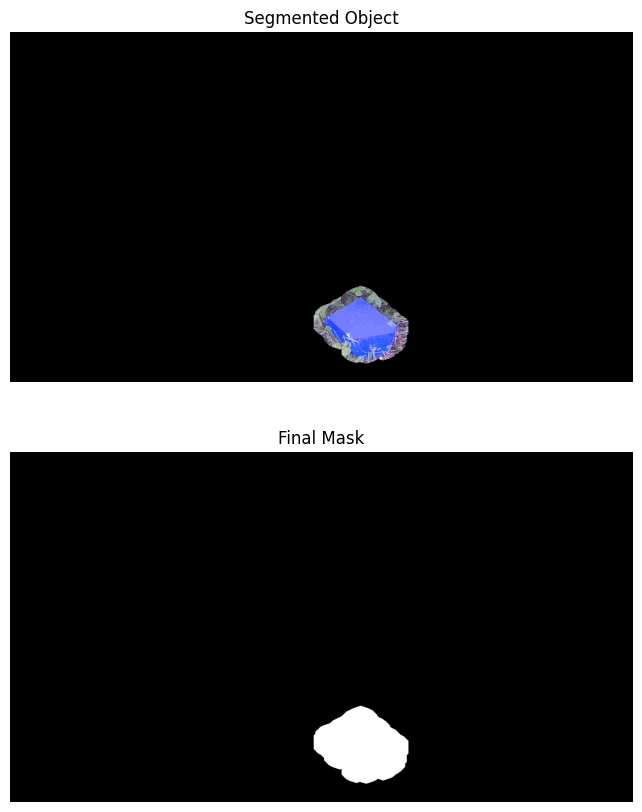

In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


image_bgr = cv2.imread("4_practice_kristall.jpg")

# Перевод в HSV
image_hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

lower_blue = np.array([110, 0, 0], np.uint8)
upper_blue = np.array([120, 255, 255], np.uint8)

# Бинарная маска по цвету
color_mask = cv2.inRange(image_hsv, lower_blue, upper_blue)



# Убираем мелкий шум (OPEN)
kernel_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
mask_opened = cv2.morphologyEx(
    color_mask,
    cv2.MORPH_OPEN,
    kernel_open,
    iterations=5
)

# Обнуляем верх изображения (не интересует)
mask_opened[:200] = 0

# Расширяем область объекта
kernel_dilate = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
mask_dilated = cv2.dilate(
    mask_opened,
    kernel_dilate,
    iterations=7
)



# Оставляем только объект интереса
result_masked = cv2.bitwise_and(
    image_bgr,
    image_bgr,
    mask=mask_dilated
)

fig, ax = plt.subplots(2, 1, figsize=(10, 10))

ax[0].imshow(cv2.cvtColor(result_masked, cv2.COLOR_BGR2RGB))
ax[0].set_title("Segmented Object")
ax[0].axis('off')

ax[1].imshow(mask_dilated, cmap='gray')
ax[1].set_title("Final Mask")
ax[1].axis('off')

plt.show()
